# Project Name : Premium prediction for Health insurance

In [1]:
# ML Project Pipeline
# Data Loading -> Undertstand Data (EDA) -> Data Cleaning -> Train ML model -> Deploy model

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Task-1 : Data loading

In [3]:
df = pd.read_excel("premiums.xlsx")
df

,Age,Gender,Region,Marital_status,Number Of Dependants,BMI_Category,Smoking_Status,Employment_Status,Income_Level,Income_Lakhs,Medical History,Insurance_Plan,Annual_Premium_Amount
0,26,Male,Northwest,Unmarried,0,Normal,No Smoking,Salaried,<10L,6,Diabetes,Bronze,9053
1,29,Female,Southeast,Married,2,Obesity,Regular,Salaried,<10L,6,Diabetes,Bronze,16339
2,49,Female,Northeast,Married,2,Normal,No Smoking,Self-Employed,10L - 25L,20,High blood pressure,Silver,18164
3,30,Female,Southeast,Married,3,Normal,No Smoking,Salaried,> 40L,77,No Disease,Gold,20303
4,18,Male,Northeast,Unmarried,0,Overweight,Regular,Self-Employed,> 40L,99,High blood pressure,Silver,13365
...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,24,Female,Northwest,Unmarried,0,Underweight,No Smoking,Self-Employed,25L - 40L,35,No Disease,Bronze,9111
49996,47,Female,Southeast,Married,2,Normal,No Smoking,Salaried,> 40L,82,Thyroid,Gold,27076
49997,21,Male,Northwest,Unmarried,0,Normal,Regular,Freelancer,25L - 40L,32,No Disease,Bronze,8564
49998,18,Male,Northwest,Unmarried,2,Normal,No Smoking,Salaried,10L - 25L,20,No Disease,Bronze,9490


In [4]:
df.shape

(50000, 13)

In [5]:
df.columns

Index(['Age', 'Gender', 'Region', 'Marital_status', 'Number Of Dependants',
       'BMI_Category', 'Smoking_Status', 'Employment_Status', 'Income_Level',
       'Income_Lakhs', 'Medical History', 'Insurance_Plan',
       'Annual_Premium_Amount'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   Age                    50000 non-null  int64 
 1   Gender                 50000 non-null  object
 2   Region                 50000 non-null  object
 3   Marital_status         50000 non-null  object
 4   Number Of Dependants   50000 non-null  int64 
 5   BMI_Category           50000 non-null  object
 6   Smoking_Status         49989 non-null  object
 7   Employment_Status      49998 non-null  object
 8   Income_Level           49987 non-null  object
 9   Income_Lakhs           50000 non-null  int64 
 10  Medical History        50000 non-null  object
 11  Insurance_Plan         50000 non-null  object
 12  Annual_Premium_Amount  50000 non-null  int64 
dtypes: int64(4), object(9)
memory usage: 5.0+ MB


# Handling Null values

In [7]:
df.isnull().sum()

Age                       0
Gender                    0
Region                    0
Marital_status            0
Number Of Dependants      0
BMI_Category              0
Smoking_Status           11
Employment_Status         2
Income_Level             13
Income_Lakhs              0
Medical History           0
Insurance_Plan            0
Annual_Premium_Amount     0
dtype: int64

In [8]:
df.dropna(inplace = True)

In [9]:
df.isnull().sum()

Age                      0
Gender                   0
Region                   0
Marital_status           0
Number Of Dependants     0
BMI_Category             0
Smoking_Status           0
Employment_Status        0
Income_Level             0
Income_Lakhs             0
Medical History          0
Insurance_Plan           0
Annual_Premium_Amount    0
dtype: int64

In [10]:
df.shape

(49976, 13)

# Handling Duplicate records

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
# describe the statistical information about the data
df.describe()

,Age,Number Of Dependants,Income_Lakhs,Annual_Premium_Amount
count,49976.000000,49976.000000,49976.000000,49976.000000
mean,34.591764,1.711842,23.021150,15766.810189
std,15.000378,1.498195,24.221794,8419.995271
min,18.000000,-3.000000,1.000000,3501.000000
25%,22.000000,0.000000,7.000000,8607.750000
50%,31.000000,2.000000,17.000000,13928.000000
75%,45.000000,3.000000,31.000000,22273.500000
max,356.000000,5.000000,930.000000,43471.000000


# Handling the inconsistant data

In [13]:
df.columns

Index(['Age', 'Gender', 'Region', 'Marital_status', 'Number Of Dependants',
       'BMI_Category', 'Smoking_Status', 'Employment_Status', 'Income_Level',
       'Income_Lakhs', 'Medical History', 'Insurance_Plan',
       'Annual_Premium_Amount'],
      dtype='object')

In [14]:
# Handle number of dependents

# Query: Print all the records where number of dependent < 0.

df[df["Number Of Dependants"] < 0]

,Age,Gender,Region,Marital_status,Number Of Dependants,BMI_Category,Smoking_Status,Employment_Status,Income_Level,Income_Lakhs,Medical History,Insurance_Plan,Annual_Premium_Amount
402,23,Female,Southwest,Unmarried,-3,Underweight,No Smoking,Freelancer,10L - 25L,18,No Disease,Silver,9309
2245,18,Male,Southwest,Unmarried,-3,Overweight,No Smoking,Freelancer,25L - 40L,28,No Disease,Silver,8095
2323,19,Male,Northwest,Unmarried,-3,Underweight,No Smoking,Freelancer,25L - 40L,40,No Disease,Bronze,4641
2986,34,Female,Southeast,Married,-1,Underweight,Regular,Self-Employed,25L - 40L,35,High blood pressure & Heart disease,Silver,22995
3756,41,Male,Southwest,Married,-1,Obesity,Regular,Salaried,10L - 25L,21,Diabetes,Silver,22766
...,...,...,...,...,...,...,...,...,...,...,...,...,...
48062,23,Male,Northwest,Unmarried,-1,Normal,No Smoking,Freelancer,> 40L,54,No Disease,Gold,13601
48086,36,Female,Southwest,Married,-1,Obesity,Occasional,Salaried,<10L,3,Diabetes,Bronze,14422
49256,60,Female,Southwest,Married,-1,Normal,No Smoking,Self-Employed,10L - 25L,21,Thyroid,Bronze,10141
49270,34,Male,Southeast,Married,-1,Obesity,No Smoking,Self-Employed,10L - 25L,17,Diabetes & Thyroid,Silver,21816


In [15]:
df[df["Number Of Dependants"] <0]['Number Of Dependants'].unique()

array([-3, -1])

In [16]:
# convert the negative value to positive
df['Number Of Dependants'] = df['Number Of Dependants'].abs()

In [17]:
df.describe()

,Age,Number Of Dependants,Income_Lakhs,Annual_Premium_Amount
count,49976.000000,49976.000000,49976.000000,49976.000000
mean,34.591764,1.717284,23.021150,15766.810189
std,15.000378,1.491953,24.221794,8419.995271
min,18.000000,0.000000,1.000000,3501.000000
25%,22.000000,0.000000,7.000000,8607.750000
50%,31.000000,2.000000,17.000000,13928.000000
75%,45.000000,3.000000,31.000000,22273.500000
max,356.000000,5.000000,930.000000,43471.000000


# Handling the Outliers

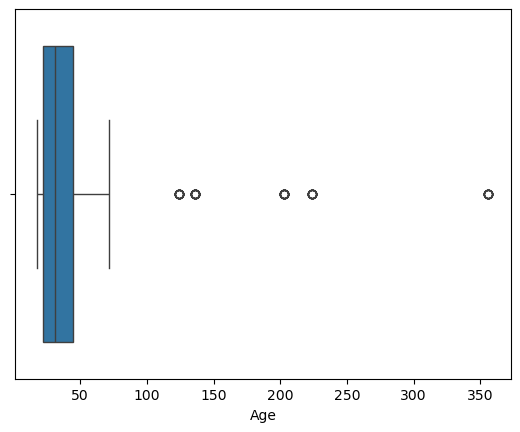

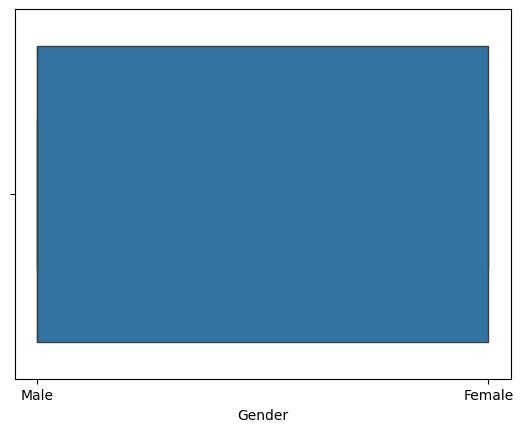

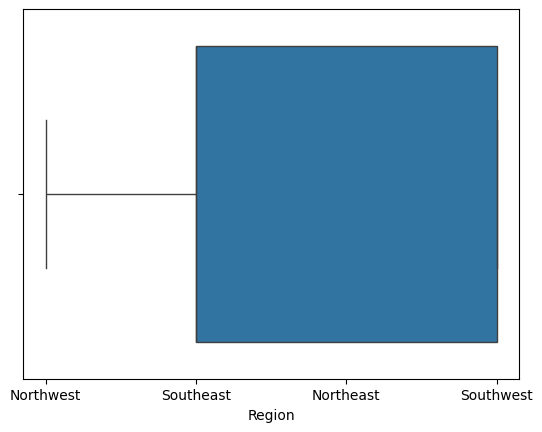

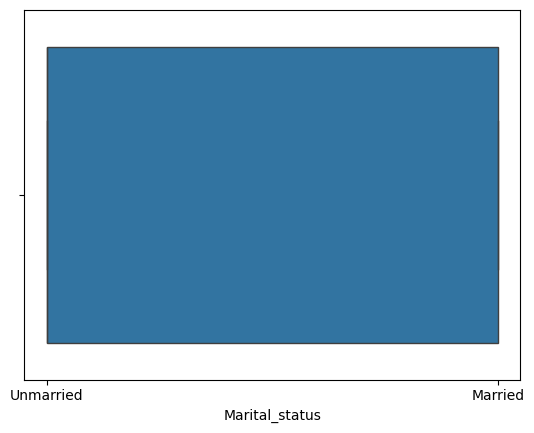

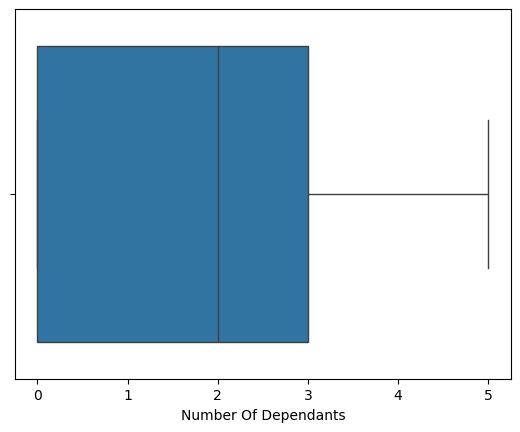

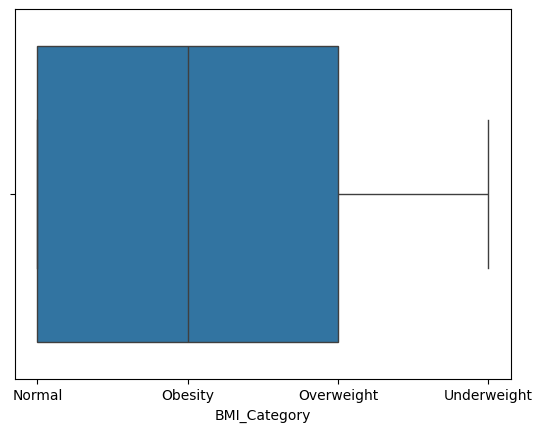

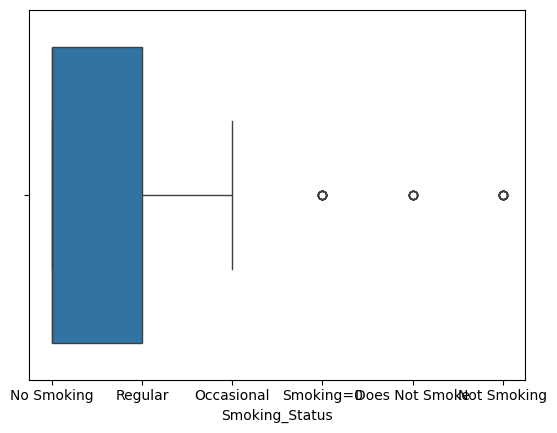

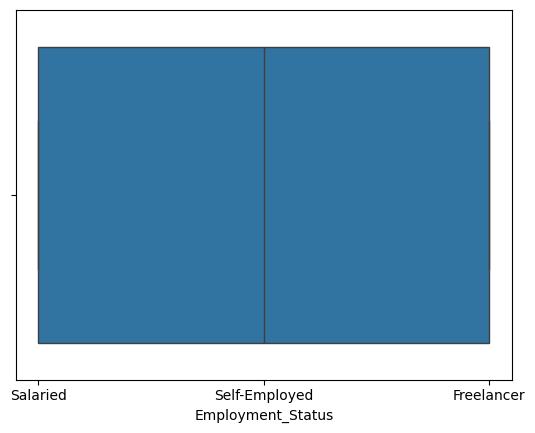

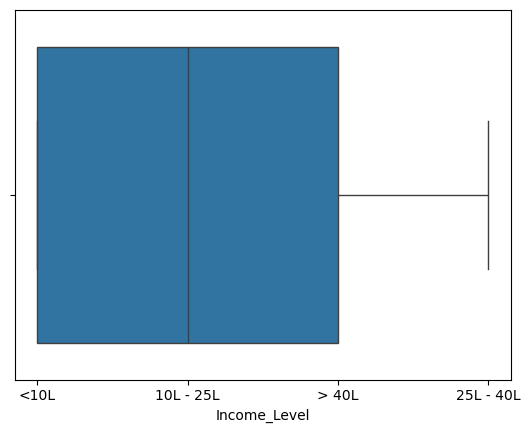

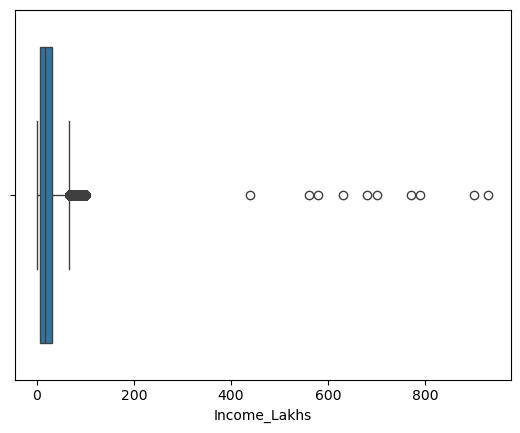

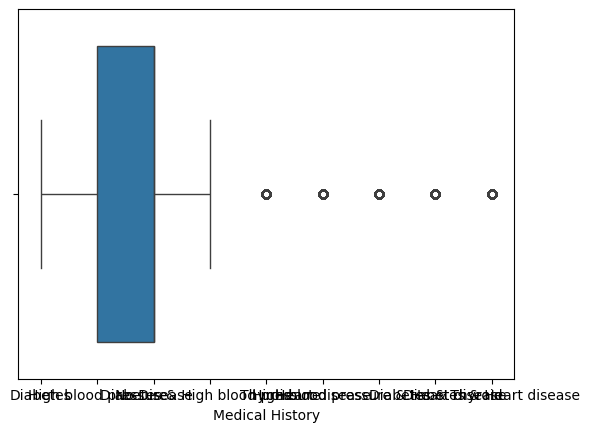

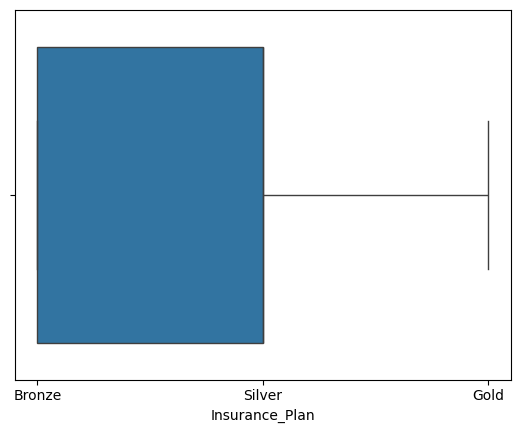

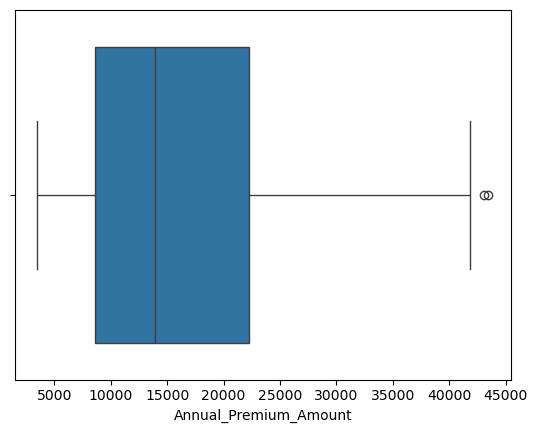

In [18]:
for col in df.columns:
    sns.boxplot(x = df[col])
    plt.show()

In [19]:
# Handle the outlier in Age column

# Query : Find the records where Age > 100
df[df.Age > 100].shape

(58, 13)

In [20]:
# find the unique values Age > 100
df[df.Age > 100].Age.unique()

array([224, 124, 136, 203, 356])

In [21]:
median = df.Age.median()
median

31.0

In [22]:
df.loc[df.Age > 100, "Age"] = median

In [23]:
df[df.Age > 100].sum()

Age                      0
Gender                   0
Region                   0
Marital_status           0
Number Of Dependants     0
BMI_Category             0
Smoking_Status           0
Employment_Status        0
Income_Level             0
Income_Lakhs             0
Medical History          0
Insurance_Plan           0
Annual_Premium_Amount    0
dtype: object

In [24]:
df.describe()

,Age,Number Of Dependants,Income_Lakhs,Annual_Premium_Amount
count,49976.000000,49976.000000,49976.000000,49976.000000
mean,34.397891,1.717284,23.021150,15766.810189
std,13.674149,1.491953,24.221794,8419.995271
min,18.000000,0.000000,1.000000,3501.000000
25%,22.000000,0.000000,7.000000,8607.750000
50%,31.000000,2.000000,17.000000,13928.000000
75%,45.000000,3.000000,31.000000,22273.500000
max,72.000000,5.000000,930.000000,43471.000000


In [25]:
# Find the number of records where income > 100 (1cr)
df[df.Income_Lakhs > 100].Income_Lakhs.count()

np.int64(10)

In [26]:
df[df.Income_Lakhs > 100].Income_Lakhs.unique()

array([560, 440, 630, 900, 930, 580, 700, 790, 770, 680])

In [27]:
# delete the records where income > 100
# Keeping those records where income <= 100
df = df[df.Income_Lakhs <= 100]

In [28]:
df[df.Income_Lakhs > 100].Income_Lakhs.count()

np.int64(0)

In [29]:
df.describe()

,Age,Number Of Dependants,Income_Lakhs,Annual_Premium_Amount
count,49966.000000,49966.000000,49966.000000,49966.000000
mean,34.397630,1.717308,22.886063,15765.961574
std,13.674151,1.491911,22.166488,8419.532784
min,18.000000,0.000000,1.000000,3501.000000
25%,22.000000,0.000000,7.000000,8607.250000
50%,31.000000,2.000000,17.000000,13928.000000
75%,45.000000,3.000000,31.000000,22272.000000
max,72.000000,5.000000,100.000000,43471.000000


In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 49966 entries, 0 to 49999
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   Age                    49966 non-null  int64 
 1   Gender                 49966 non-null  object
 2   Region                 49966 non-null  object
 3   Marital_status         49966 non-null  object
 4   Number Of Dependants   49966 non-null  int64 
 5   BMI_Category           49966 non-null  object
 6   Smoking_Status         49966 non-null  object
 7   Employment_Status      49966 non-null  object
 8   Income_Level           49966 non-null  object
 9   Income_Lakhs           49966 non-null  int64 
 10  Medical History        49966 non-null  object
 11  Insurance_Plan         49966 non-null  object
 12  Annual_Premium_Amount  49966 non-null  int64 
dtypes: int64(4), object(9)
memory usage: 5.3+ MB


In [31]:
# segregating categorical column names
categorical_columns = df.select_dtypes(include = ['object']).columns
categorical_columns

Index(['Gender', 'Region', 'Marital_status', 'BMI_Category', 'Smoking_Status',
       'Employment_Status', 'Income_Level', 'Medical History',
       'Insurance_Plan'],
      dtype='object')

In [32]:
# unique values in each categorical column
for col in categorical_columns:
    print(col, " : ", df[col].unique())

Gender  :  ['Male' 'Female']
Region  :  ['Northwest' 'Southeast' 'Northeast' 'Southwest']
Marital_status  :  ['Unmarried' 'Married']
BMI_Category  :  ['Normal' 'Obesity' 'Overweight' 'Underweight']
Smoking_Status  :  ['No Smoking' 'Regular' 'Occasional' 'Smoking=0' 'Does Not Smoke'
 'Not Smoking']
Employment_Status  :  ['Salaried' 'Self-Employed' 'Freelancer']
Income_Level  :  ['<10L' '10L - 25L' '> 40L' '25L - 40L']
Medical History  :  ['Diabetes' 'High blood pressure' 'No Disease'
 'Diabetes & High blood pressure' 'Thyroid' 'Heart disease'
 'High blood pressure & Heart disease' 'Diabetes & Thyroid'
 'Diabetes & Heart disease']
Insurance_Plan  :  ['Bronze' 'Silver' 'Gold']


In [33]:
# Query: replace the 'Smoking=0' 'Does Not Smoke' 'Not Smoking'  WITH 'No Smoking'
df['Smoking_Status'] = df['Smoking_Status'].replace({'Smoking=0' : 'No Smoking', 
                                                     'Does Not Smoke' : 'No Smoking', 
                                                     'Not Smoking' : 'No Smoking'  })

df['Smoking_Status'].unique()

C:\Users\Prikshit_Ishi\AppData\Local\Temp\ipykernel_9028\3965679239.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Smoking_Status'] = df['Smoking_Status'].replace({'Smoking=0' : 'No Smoking',


array(['No Smoking', 'Regular', 'Occasional'], dtype=object)

# Step-3 : Feature engineering

In [34]:
df1 = df.copy()

# Converting categorical columns into Numerical

In [35]:
# converting Medical history categories to numeric value
"""
Medical History  :  ['Diabetes' 'High blood pressure' 'No Disease'
 'Diabetes & High blood pressure' 'Thyroid' 'Heart disease'
 'High blood pressure & Heart disease' 'Diabetes & Thyroid'
 'Diabetes & Heart disease']
"""
risk_score = {
                'Diabetes' : 6,
                'High blood pressure' : 6,
                'Heart disease' : 8,
                'Thyroid' : 5,
                'No Disease' : 0,
                'Diabetes & High blood pressure' : 12,
                'High blood pressure & Heart disease' : 14,
                'Diabetes & Heart disease' : 14,
                'Diabetes & Thyroid' : 11
}

df1['Medical History'] = df1['Medical History'].map(risk_score)

In [36]:
df1['Medical History'].unique()

array([ 6,  0, 12,  5,  8, 14, 11])

In [37]:
categorical_columns = df1.select_dtypes(include = ['object']).columns
categorical_columns

Index(['Gender', 'Region', 'Marital_status', 'BMI_Category', 'Smoking_Status',
       'Employment_Status', 'Income_Level', 'Insurance_Plan'],
      dtype='object')

# Apply the Ordinal encoding on "Income_Level", "Insurance_Plan"

In [38]:
# Ordinal encoding is used when their is Ranking in the data

In [39]:
df1['Insurance_Plan'].unique()

array(['Bronze', 'Silver', 'Gold'], dtype=object)

In [40]:
from sklearn.preprocessing import OrdinalEncoder

encoder = OrdinalEncoder(categories =[['<10L', '10L - 25L',  '25L - 40L', '> 40L']])
df1['Income_Level'] = encoder.fit_transform(df1[['Income_Level']])

In [41]:
encoder = OrdinalEncoder(categories =[['Bronze', 'Silver', 'Gold']])
df1['Insurance_Plan'] = encoder.fit_transform(df1[['Insurance_Plan']])

In [42]:
df1

,Age,Gender,Region,Marital_status,Number Of Dependants,BMI_Category,Smoking_Status,Employment_Status,Income_Level,Income_Lakhs,Medical History,Insurance_Plan,Annual_Premium_Amount
0,26,Male,Northwest,Unmarried,0,Normal,No Smoking,Salaried,0.0,6,6,0.0,9053
1,29,Female,Southeast,Married,2,Obesity,Regular,Salaried,0.0,6,6,0.0,16339
2,49,Female,Northeast,Married,2,Normal,No Smoking,Self-Employed,1.0,20,6,1.0,18164
3,30,Female,Southeast,Married,3,Normal,No Smoking,Salaried,3.0,77,0,2.0,20303
4,18,Male,Northeast,Unmarried,0,Overweight,Regular,Self-Employed,3.0,99,6,1.0,13365
...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,24,Female,Northwest,Unmarried,0,Underweight,No Smoking,Self-Employed,2.0,35,0,0.0,9111
49996,47,Female,Southeast,Married,2,Normal,No Smoking,Salaried,3.0,82,5,2.0,27076
49997,21,Male,Northwest,Unmarried,0,Normal,Regular,Freelancer,2.0,32,0,0.0,8564
49998,18,Male,Northwest,Unmarried,2,Normal,No Smoking,Salaried,1.0,20,0,0.0,9490


# Apply Label encoder on "Region" and "BMI_Category"

In [43]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

df1['Region'] = encoder.fit_transform(df1['Region'])
df1['BMI_Category'] = encoder.fit_transform(df1['BMI_Category'])
df1

,Age,Gender,Region,Marital_status,Number Of Dependants,BMI_Category,Smoking_Status,Employment_Status,Income_Level,Income_Lakhs,Medical History,Insurance_Plan,Annual_Premium_Amount
0,26,Male,1,Unmarried,0,0,No Smoking,Salaried,0.0,6,6,0.0,9053
1,29,Female,2,Married,2,1,Regular,Salaried,0.0,6,6,0.0,16339
2,49,Female,0,Married,2,0,No Smoking,Self-Employed,1.0,20,6,1.0,18164
3,30,Female,2,Married,3,0,No Smoking,Salaried,3.0,77,0,2.0,20303
4,18,Male,0,Unmarried,0,2,Regular,Self-Employed,3.0,99,6,1.0,13365
...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,24,Female,1,Unmarried,0,3,No Smoking,Self-Employed,2.0,35,0,0.0,9111
49996,47,Female,2,Married,2,0,No Smoking,Salaried,3.0,82,5,2.0,27076
49997,21,Male,1,Unmarried,0,0,Regular,Freelancer,2.0,32,0,0.0,8564
49998,18,Male,1,Unmarried,2,0,No Smoking,Salaried,1.0,20,0,0.0,9490


In [44]:
# Apply one hot encoding 'Gender', 'Marital_status', smoking_status', 'employment_status' 

# pd.get_dummies()

# use one hot encoding when number of categories is less in the column

In [45]:
df1 = pd.get_dummies(df1, columns = ['Gender', 'Marital_status', 'Smoking_Status', 'Employment_Status'], drop_first = True, dtype = int)
df1

# dummy variable trap : by deleting first column, we handle the dummy varaible trap.

,Age,Region,Number Of Dependants,BMI_Category,Income_Level,Income_Lakhs,Medical History,Insurance_Plan,Annual_Premium_Amount,Gender_Male,Marital_status_Unmarried,Smoking_Status_Occasional,Smoking_Status_Regular,Employment_Status_Salaried,Employment_Status_Self-Employed
0,26,1,0,0,0.0,6,6,0.0,9053,1,1,0,0,1,0
1,29,2,2,1,0.0,6,6,0.0,16339,0,0,0,1,1,0
2,49,0,2,0,1.0,20,6,1.0,18164,0,0,0,0,0,1
3,30,2,3,0,3.0,77,0,2.0,20303,0,0,0,0,1,0
4,18,0,0,2,3.0,99,6,1.0,13365,1,1,0,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,24,1,0,3,2.0,35,0,0.0,9111,0,1,0,0,0,1
49996,47,2,2,0,3.0,82,5,2.0,27076,0,0,0,0,1,0
49997,21,1,0,0,2.0,32,0,0.0,8564,1,1,0,1,0,0
49998,18,1,2,0,1.0,20,0,0.0,9490,1,1,0,0,1,0


# Remove the features which are highly correlated with each other.

<Axes: >

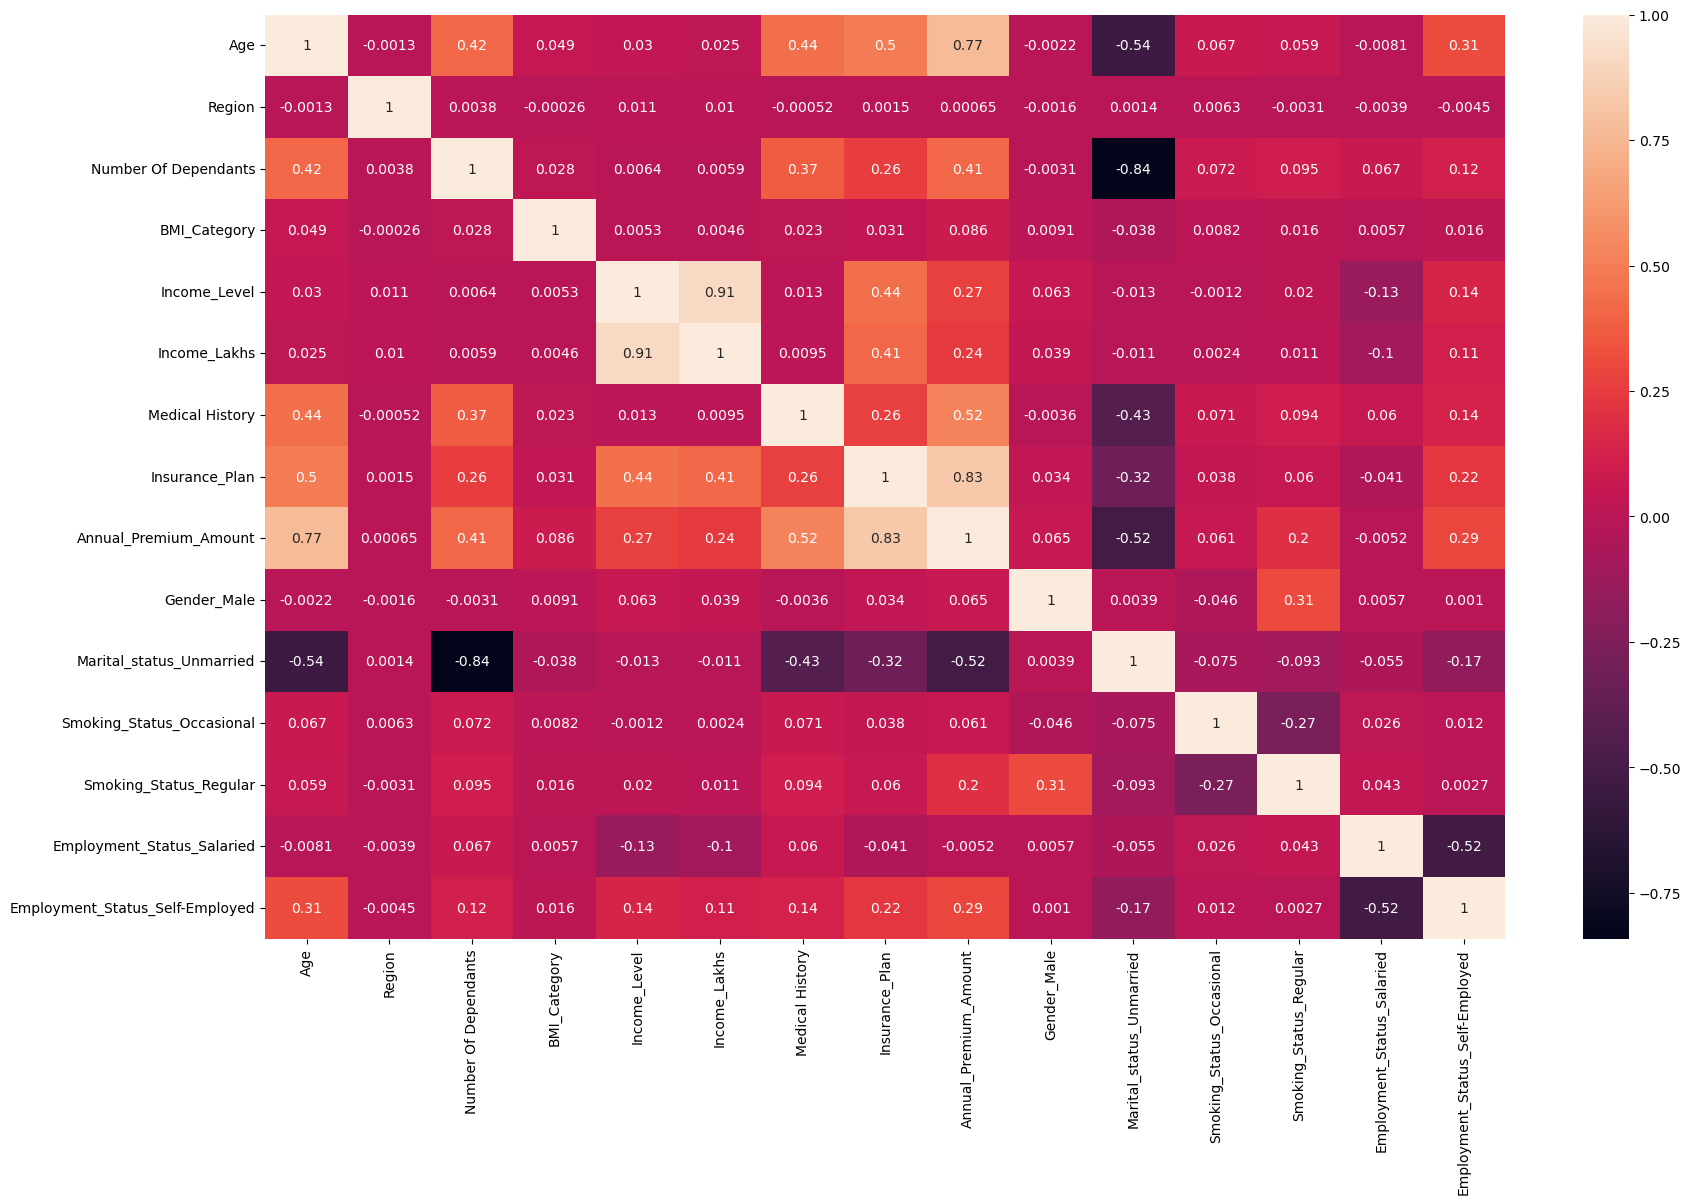

In [48]:
cm = df1.corr()

plt.figure(figsize = (20, 12))
sns.heatmap(cm, annot = True)

In [49]:
# Which columns are more than 80% (negative or positive)
# 1. Income_level & Income_Lakhs
# 2. Marital_status_unmarried & Number of dependent

# if some column is related to Target column then don't delete that column
# Actually that column will help us to find the target value.

In [50]:
df1 = df1.drop(["Income_Level", "Marital_status_Unmarried"] , axis = 1)

In [51]:
df1.columns

Index(['Age', 'Region', 'Number Of Dependants', 'BMI_Category', 'Income_Lakhs',
       'Medical History', 'Insurance_Plan', 'Annual_Premium_Amount',
       'Gender_Male', 'Smoking_Status_Occasional', 'Smoking_Status_Regular',
       'Employment_Status_Salaried', 'Employment_Status_Self-Employed'],
      dtype='object')

# Scaling the data

In [46]:
df1.columns

Index(['Age', 'Region', 'Number Of Dependants', 'BMI_Category', 'Income_Level',
       'Income_Lakhs', 'Medical History', 'Insurance_Plan',
       'Annual_Premium_Amount', 'Gender_Male', 'Marital_status_Unmarried',
       'Smoking_Status_Occasional', 'Smoking_Status_Regular',
       'Employment_Status_Salaried', 'Employment_Status_Self-Employed'],
      dtype='object')

In [47]:
x = df1.drop("Annual_Premium_Amount", axis = 1)


# Bring all the values in the range of 0 to 1
from sklearn.preprocessing import MinMaxScaler

cols_to_scale = ['Age', 'Region', 'Number Of Dependants', 'BMI_Category', 'Income_Level',
       'Income_Lakhs', 'Medical History', 'Insurance_Plan',
       'Gender_Male', 'Marital_status_Unmarried',
       'Smoking_Status_Occasional', 'Smoking_Status_Regular',
       'Employment_Status_Salaried', 'Employment_Status_Self-Employed']
scaler = MinMaxScaler()

df1[cols_to_scale] = scaler.fit_transform(df1[cols_to_scale])
df1

,Age,Region,Number Of Dependants,BMI_Category,Income_Level,Income_Lakhs,Medical History,Insurance_Plan,Annual_Premium_Amount,Gender_Male,Marital_status_Unmarried,Smoking_Status_Occasional,Smoking_Status_Regular,Employment_Status_Salaried,Employment_Status_Self-Employed
0,0.148148,0.333333,0.0,0.000000,0.000000,0.050505,0.428571,0.0,9053,1.0,1.0,0.0,0.0,1.0,0.0
1,0.203704,0.666667,0.4,0.333333,0.000000,0.050505,0.428571,0.0,16339,0.0,0.0,0.0,1.0,1.0,0.0
2,0.574074,0.000000,0.4,0.000000,0.333333,0.191919,0.428571,0.5,18164,0.0,0.0,0.0,0.0,0.0,1.0
3,0.222222,0.666667,0.6,0.000000,1.000000,0.767677,0.000000,1.0,20303,0.0,0.0,0.0,0.0,1.0,0.0
4,0.000000,0.000000,0.0,0.666667,1.000000,0.989899,0.428571,0.5,13365,1.0,1.0,0.0,1.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,0.111111,0.333333,0.0,1.000000,0.666667,0.343434,0.000000,0.0,9111,0.0,1.0,0.0,0.0,0.0,1.0
49996,0.537037,0.666667,0.4,0.000000,1.000000,0.818182,0.357143,1.0,27076,0.0,0.0,0.0,0.0,1.0,0.0
49997,0.055556,0.333333,0.0,0.000000,0.666667,0.313131,0.000000,0.0,8564,1.0,1.0,0.0,1.0,0.0,0.0
49998,0.000000,0.333333,0.4,0.000000,0.333333,0.191919,0.000000,0.0,9490,1.0,1.0,0.0,0.0,1.0,0.0


# Step-4 : Training model

In [52]:
# libraries
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

In [53]:
# put feature in x and target in y
x = df1.drop('Annual_Premium_Amount', axis = 1)
y = df1.Annual_Premium_Amount

In [54]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 42)

In [55]:
# train the model
linear_obj =  LinearRegression()
linear_obj.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](12,)","[12175.95, 32.59, 717.79,..., 2345.14, 225.05, 431.67]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](12,)","['Age','Region','Number Of Dependants',...,'Smoking_Status_Regular', 'Employment_Status_Salaried','Employment_Status_Self-Employed']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,3911
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,12
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,12


In [56]:
lr_score = linear_obj.score(x_test, y_test)
lr_score

0.9102146048025952

# Model-2 : XGBoost

In [57]:
from xgboost import XGBRegressor

In [58]:
XGB_obj =  XGBRegressor()

In [59]:
XGB_obj.fit(x_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [60]:
XGB_score = XGB_obj.score(x_test, y_test)
XGB_score

0.9809945225715637

In [62]:
XGB_obj.predict([[0.148148,	0.333333,	0.0,	0.000000,	0.050505,	0.428571,	0.0,	1.0,	0.0,	0.0,	1.0,	0.0]])

array([6681.1455], dtype=float32)

# Exporting the trained model using joblib

In [63]:
pip install joblib

In [64]:
import os 
os.getcwd()

'C:\\Users\\Prikshit_Ishi\\Complete_Data_Science\\ML_Regression_Project\\Final_Project_Codegnan'

In [65]:
from joblib import dump

dump(XGB_obj, "artifacts/model.joblib")

scaler_data = {
    'scaler' : scaler,
    'cols_to_scale' : cols_to_scale
}

dump(scaler_data, "artifacts/scaler.joblib")

['artifacts/scaler.joblib']